# 04 - Evaluation and Explainability

**Owner:** Rohan  
**Part:** E (Evaluation + Grad-CAM + t-SNE)

This notebook documents the evaluation and explainability experiments using existing results. No model retraining is performed.


## 1. Model Evaluation

MobileNetV2 was evaluated on 4,050 EuroSAT test images.

- Test Accuracy: 98.30%
- Macro-F1: 98.20%
- Correct Predictions: 3,981
- Incorrect Predictions: 69


In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Works whether Jupyter starts in the repo folder or in notebooks/.
project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
os.chdir(project_root)
RESULTS = project_root / "results"
FIGURES = RESULTS / "figures"

report = pd.read_csv(
    RESULTS / "mobilenet_v2_full_frac1_seed0_classification_report.csv",
    index_col=0
)
cm = pd.read_csv(
    RESULTS / "mobilenet_v2_full_frac1_seed0_confusion_matrix.csv",
    index_col=0
)

print("Classification Report")
display(report)

print("Confusion Matrix")
display(cm)


Classification Report


,precision,recall,f1-score,support
AnnualCrop,0.982022,0.971111,0.976536,450.000000
Forest,0.993363,0.997778,0.995565,450.000000
HerbaceousVegetation,0.986517,0.975556,0.981006,450.000000
Highway,0.973475,0.978667,0.976064,375.000000
Industrial,0.989247,0.981333,0.985274,375.000000
Pasture,0.951299,0.976667,0.963816,300.000000
PermanentCrop,0.967742,0.960000,0.963855,375.000000
Residential,0.988962,0.995556,0.992248,450.000000
River,0.989305,0.986667,0.987984,375.000000
SeaLake,0.995575,1.000000,0.997783,450.000000


Confusion Matrix


,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,437,0,0,0,0,5,7,0,0,1
Forest,0,449,1,0,0,0,0,0,0,0
HerbaceousVegetation,0,0,439,1,0,5,5,0,0,0
Highway,0,0,0,367,1,2,0,1,4,0
Industrial,0,0,1,3,368,0,0,3,0,0
Pasture,4,1,1,0,0,293,0,0,0,1
PermanentCrop,3,1,3,3,1,3,360,1,0,0
Residential,0,0,0,0,2,0,0,448,0,0
River,1,1,0,3,0,0,0,0,370,0
SeaLake,0,0,0,0,0,0,0,0,0,450


## 2. Confusion Matrix Visualization

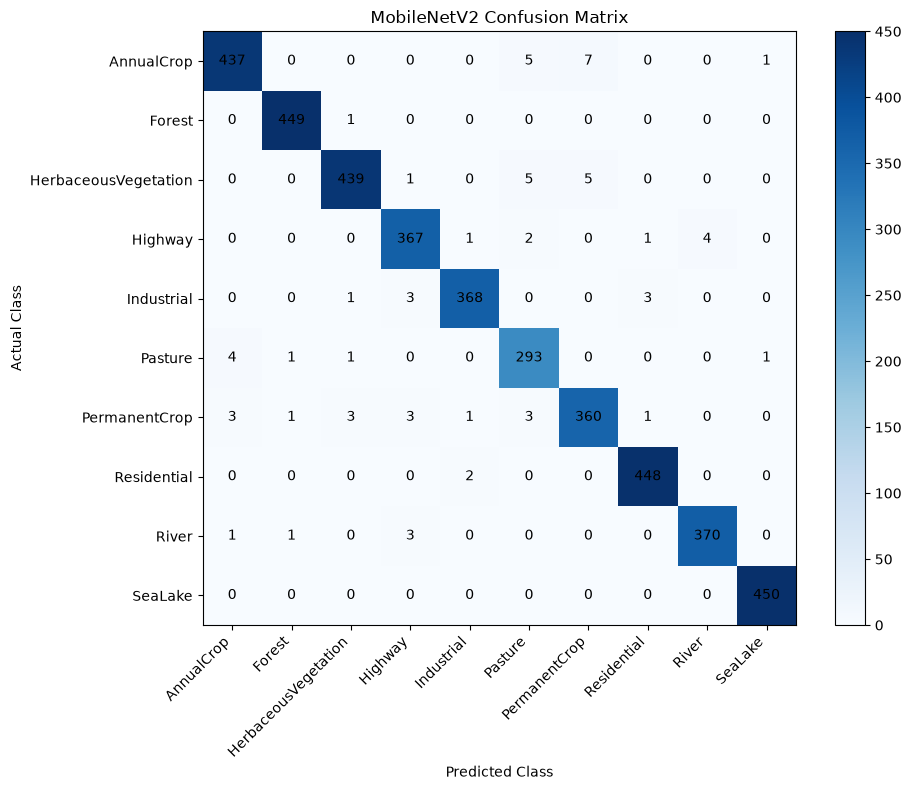

In [2]:
plt.figure(figsize=(10, 8))
plt.imshow(cm.values, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(cm.columns)), cm.columns, rotation=45, ha="right")
plt.yticks(range(len(cm.index)), cm.index)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 Confusion Matrix")

for i in range(len(cm.index)):
    for j in range(len(cm.columns)):
        plt.text(j, i, cm.iloc[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()


## 3. Misclassification Analysis

The model made 69 incorrect predictions. Agricultural classes showed the largest confusion: 36 of the 69 mistakes are among AnnualCrop, PermanentCrop, Pasture and HerbaceousVegetation. A likely reason is similar vegetation patterns (we looked at examples but did not test this).


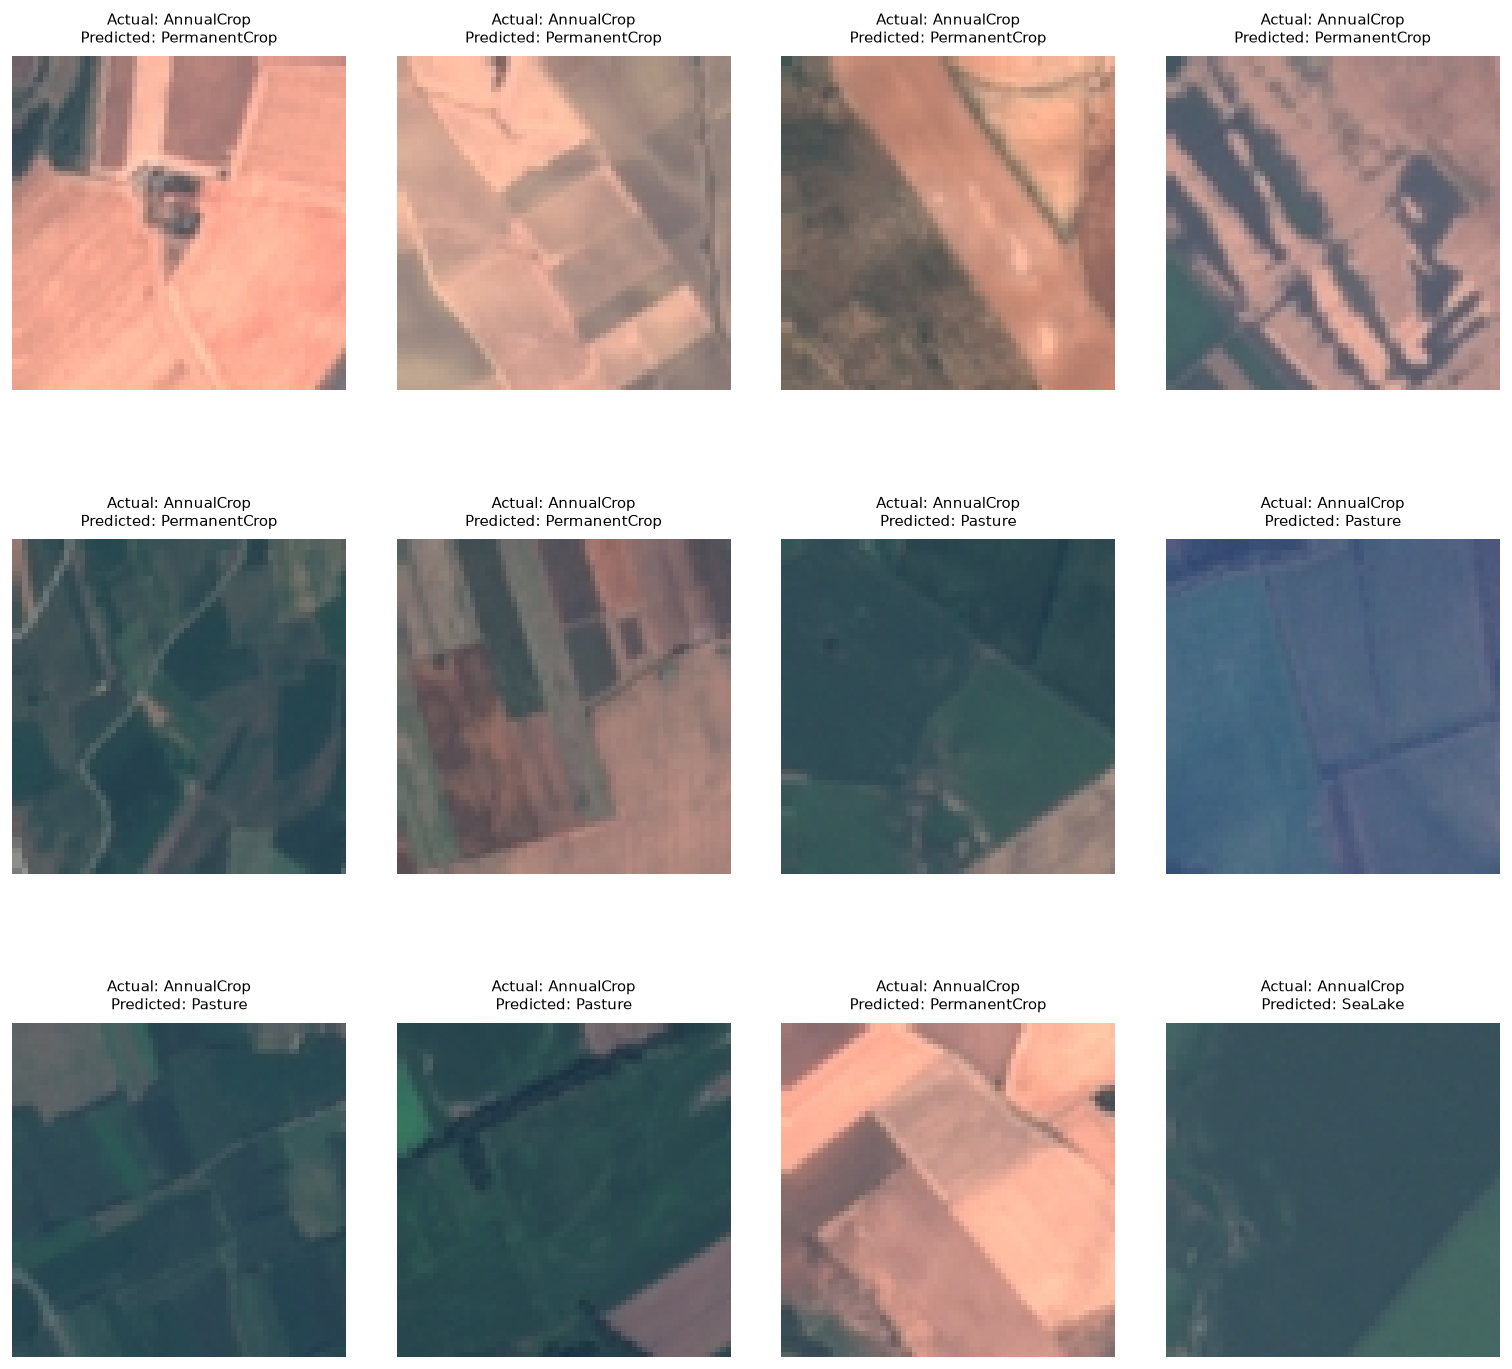

In [3]:
display(Image(filename=str(RESULTS / "misclassified_images_grid.png")))


### 3.1 Confused Class Pair Examples

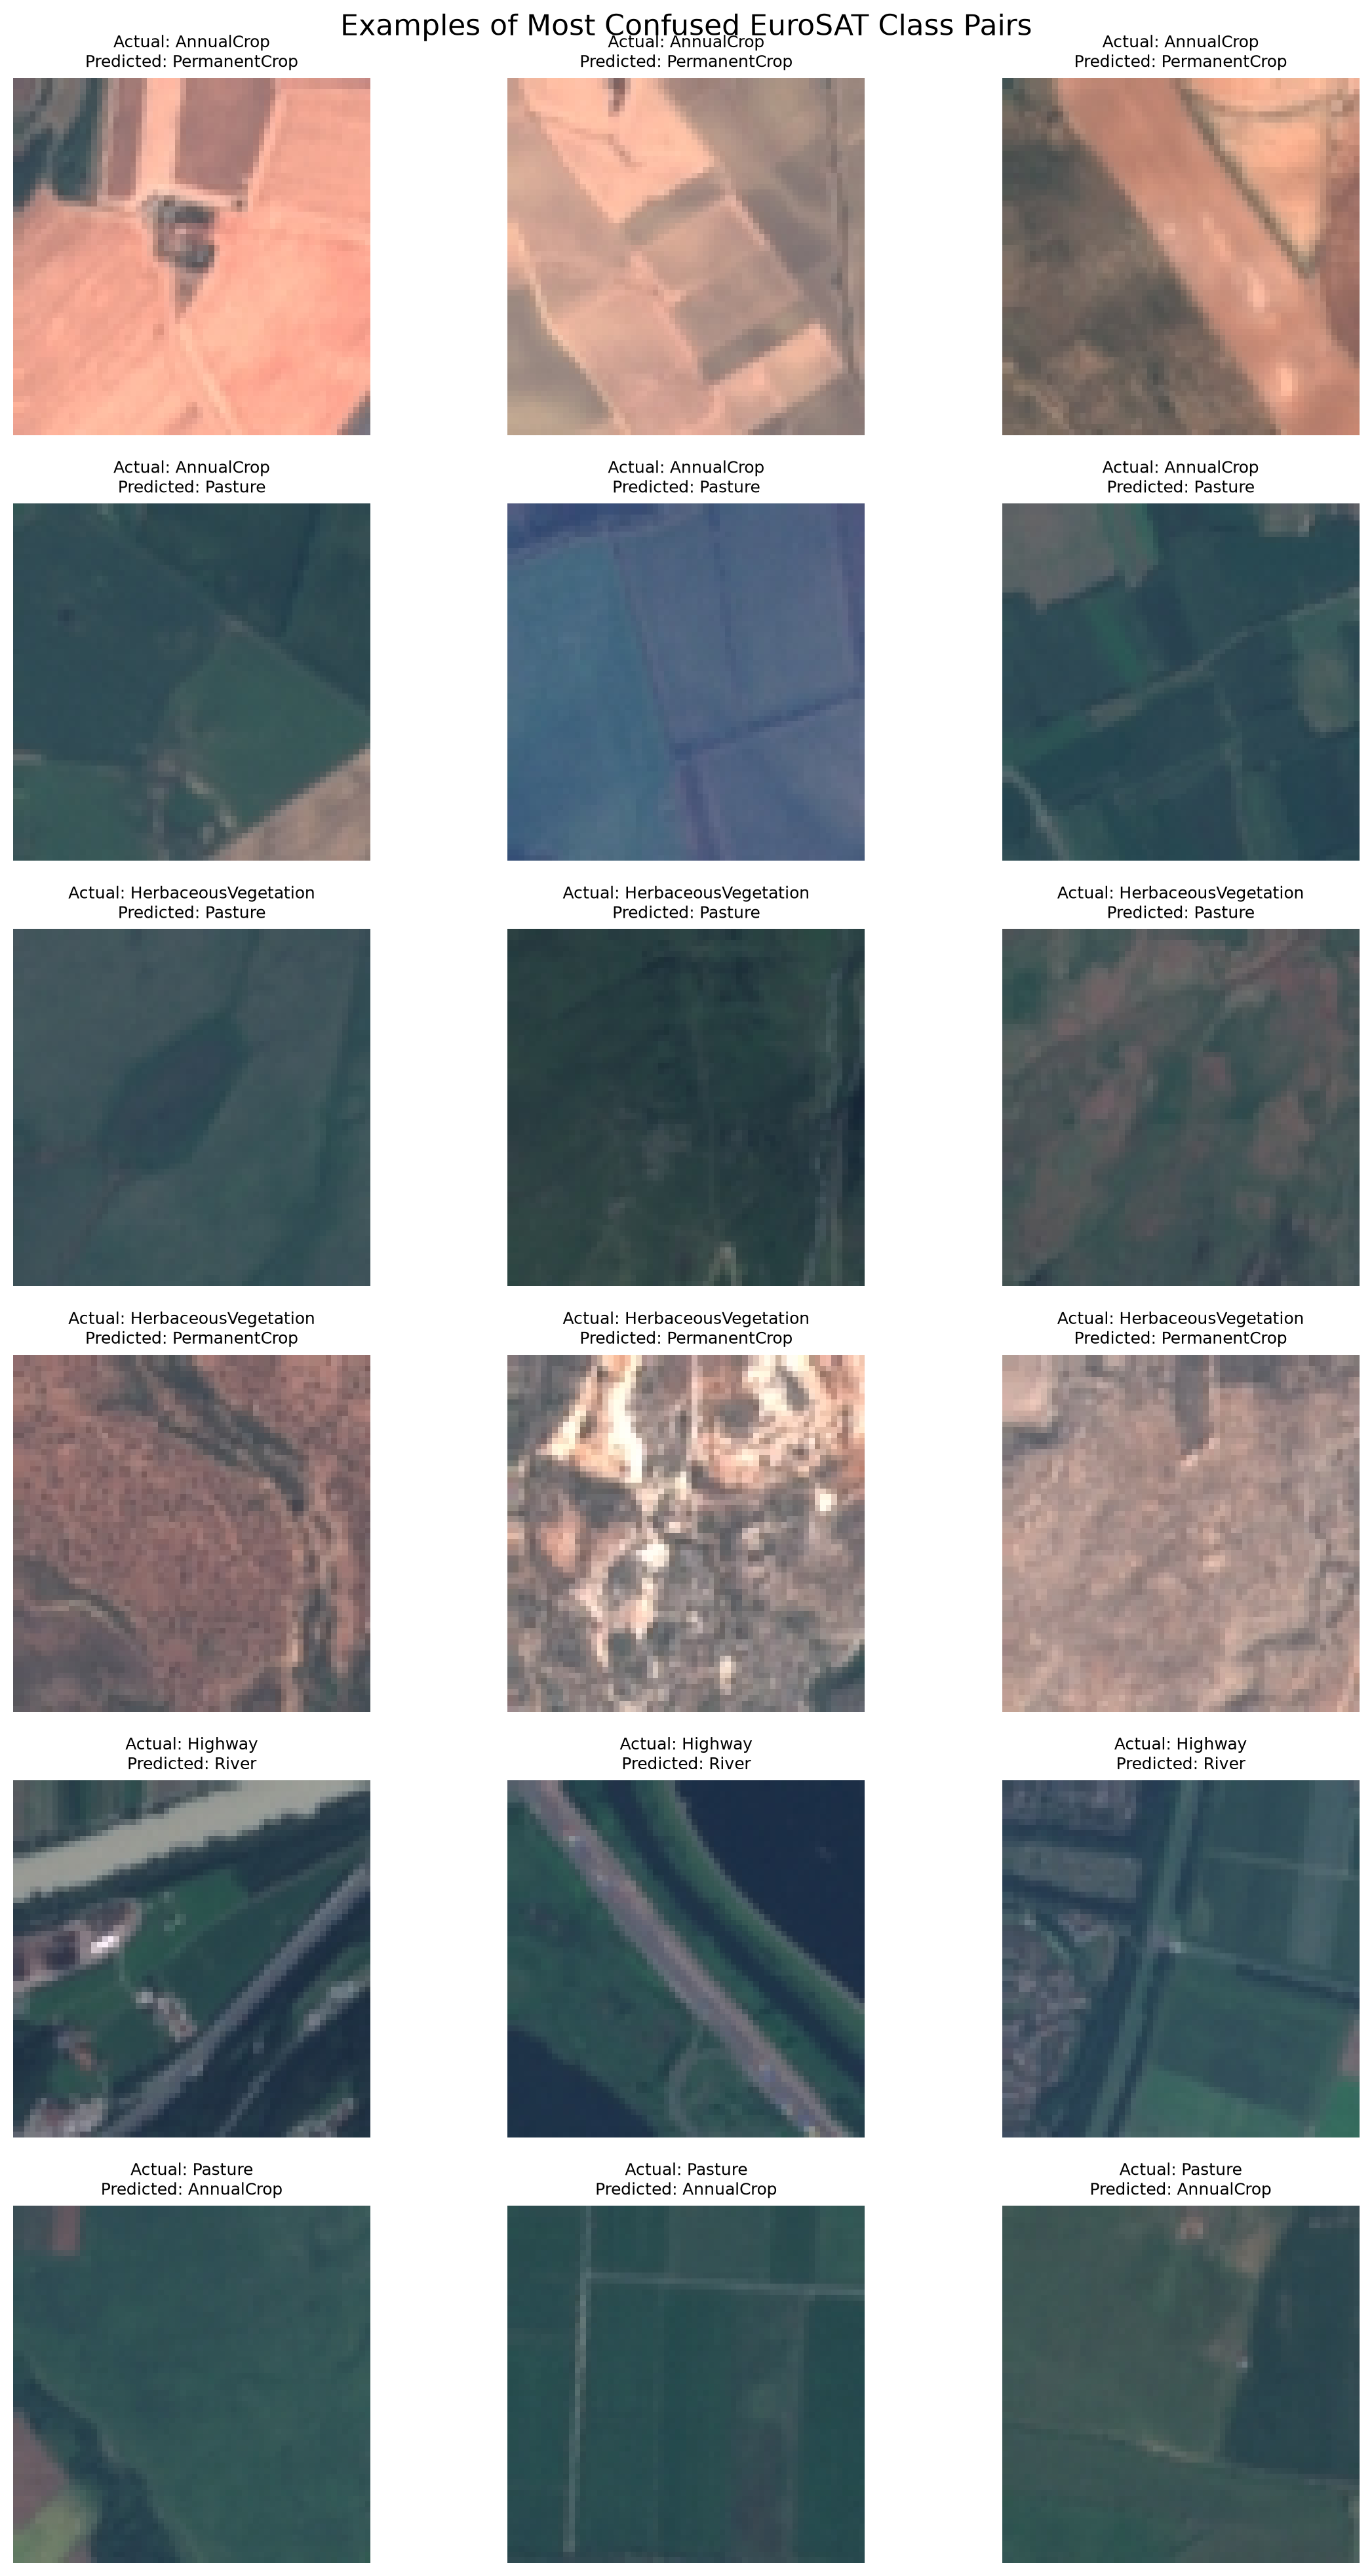

In [4]:
display(Image(filename=str(FIGURES / "confusion_pair_examples.png")))


## 4. Grad-CAM Explainability

**Read this section together with 5.1.** On this model the heat maps are only 2 x 2 cells and mostly hot in the lower-right, so they are pictures to look at, not proof of what the model sees.

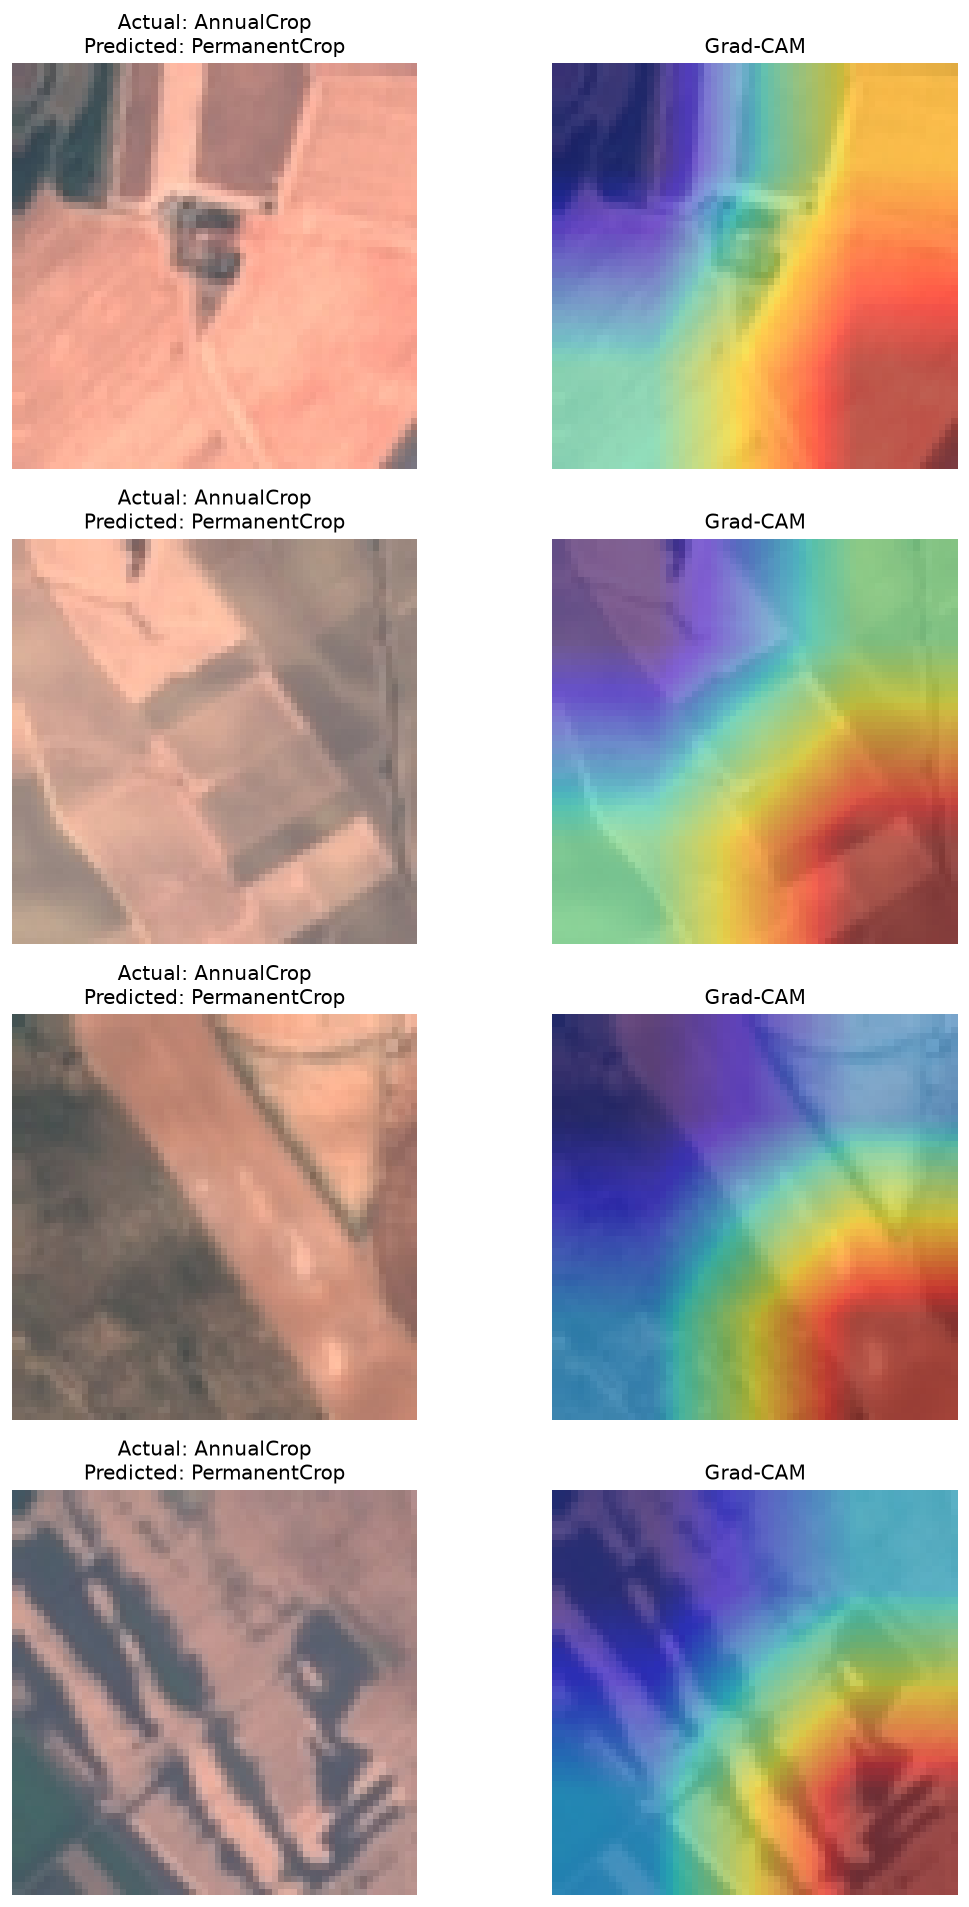

In [5]:
display(Image(filename=str(FIGURES / "gradcam_examples.png")))


### 4.1 Grad-CAM for All 10 Classes

Grad-CAM examples include correctly classified and misclassified images across the 10 EuroSAT classes. Most heat maps are hot in the lower-right part of the image, whatever the image shows (see 5.1).


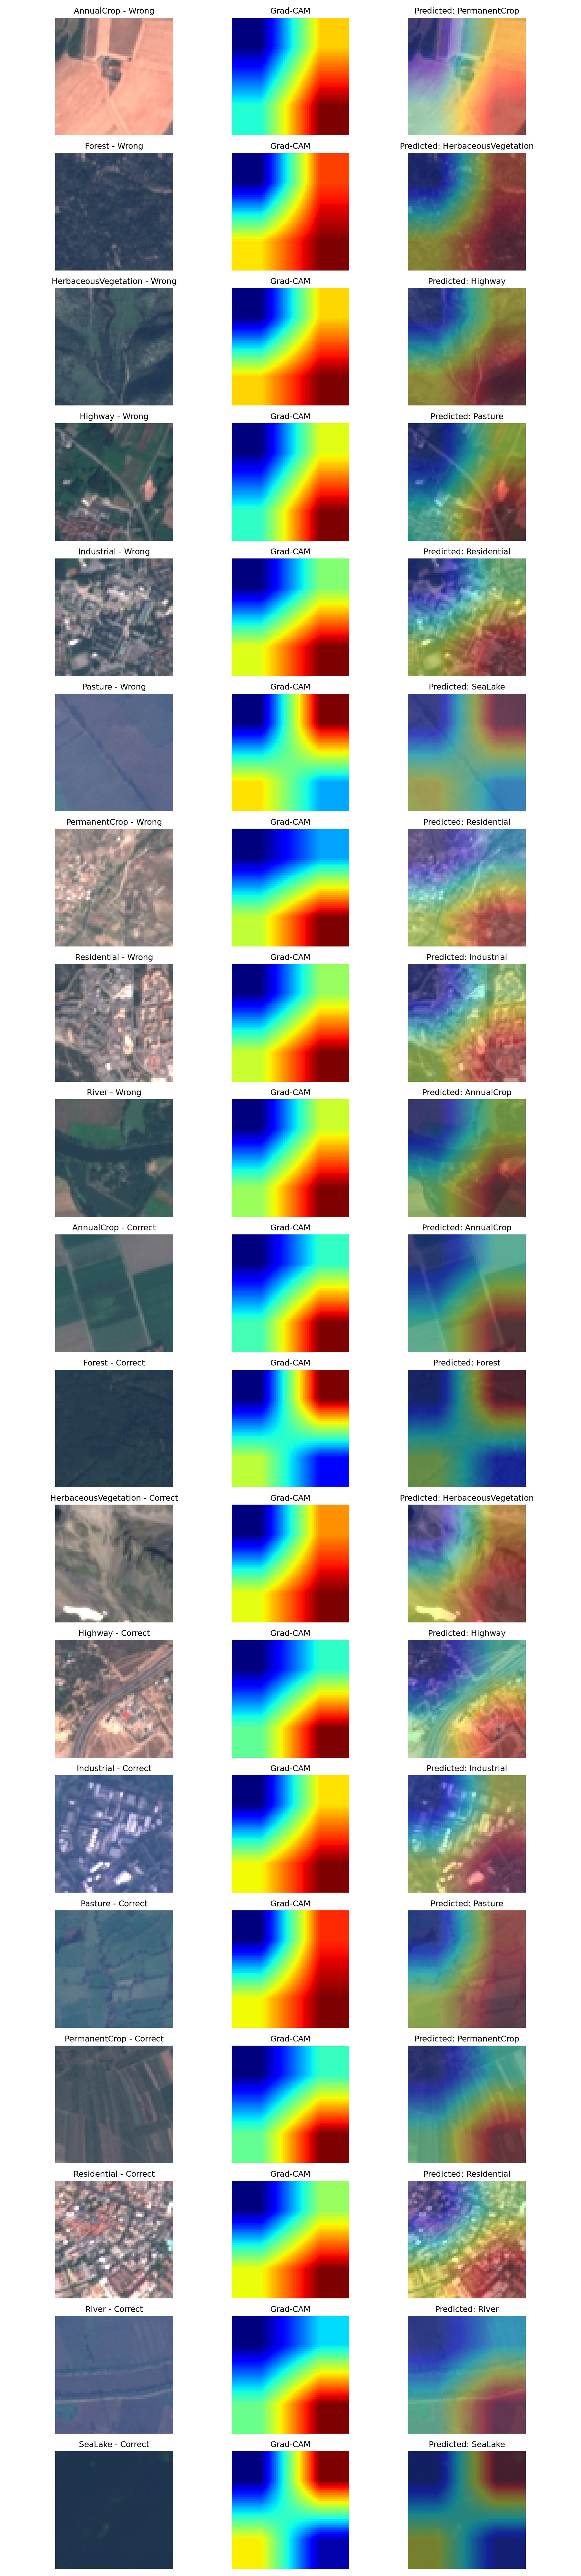

In [6]:
display(Image(filename=str(FIGURES / "gradcam_all_classes.png")))


## 5. Grad-CAM Confidence-Drop Experiment

This experiment has **no control** (no coldest-area or random-area patch), so a small drop alone does not show that the highlighted area matters. The control is in 5.1.

,path,class_name,original_confidence,masked_confidence,confidence_drop
0,eurosat/2750/Residential/Residential_136.jpg,Residential,0.999385,0.964483,0.034902
1,eurosat/2750/AnnualCrop/AnnualCrop_1877.jpg,AnnualCrop,0.998439,0.997943,0.000496
2,eurosat/2750/Industrial/Industrial_529.jpg,Industrial,0.999926,0.999956,-0.000029
3,eurosat/2750/PermanentCrop/PermanentCrop_1016.jpg,PermanentCrop,0.999930,0.997589,0.002342
4,eurosat/2750/Residential/Residential_900.jpg,Residential,1.000000,0.999996,0.000004


Number of evaluated images: 50


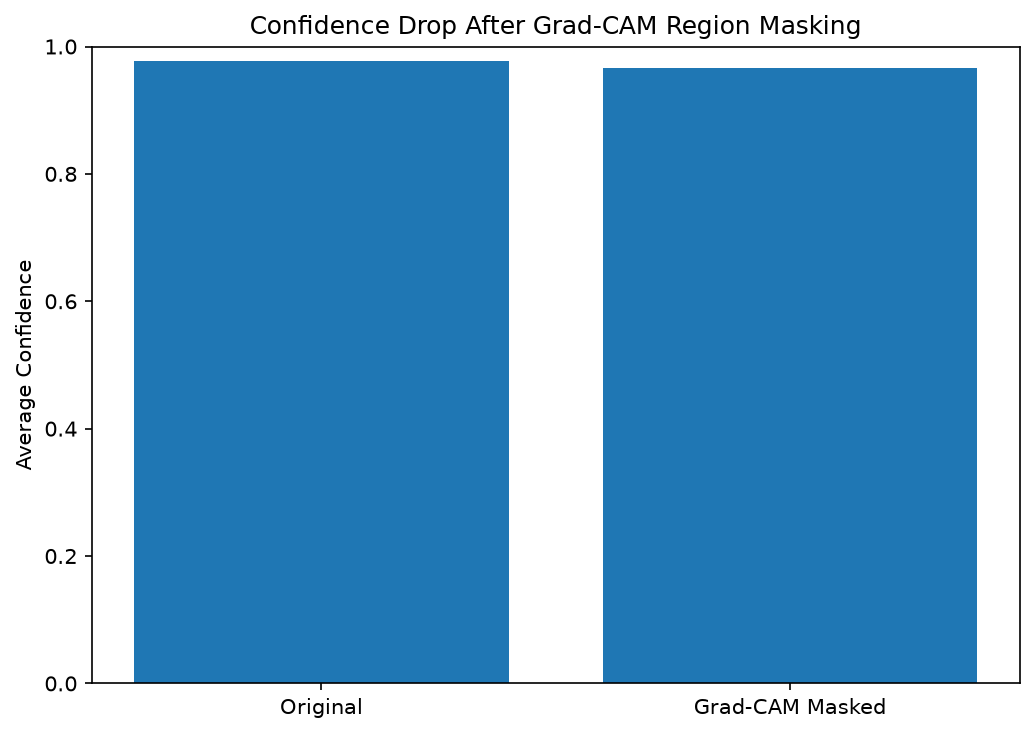

In [7]:
confidence = pd.read_csv(RESULTS / "gradcam_confidence_drop.csv")
display(confidence.head())
print("Number of evaluated images:", len(confidence))
display(Image(filename=str(FIGURES / "gradcam_confidence_drop.png")))


### 5.1 Control experiment (added by Nitin with Claude)

`python -m src.gradcam_sanity_check` hides 25% of the pixels (one solid patch) in 200 test images: the hottest area, the coldest area, or a random 32 x 32 square, and measures the fall in confidence. It also counts which quarter of the heat map is hottest. If Grad-CAM were meaningful, hiding the hottest area should hurt clearly more than hiding the coldest.

In [8]:
check = pd.read_csv(RESULTS / 'gradcam_sanity_check.csv')
summary = pd.DataFrame({
    'mean confidence drop': [check[f'drop_{n}'].mean() for n in ('hottest', 'coldest', 'random_square')],
    'prediction changed (of %d)' % len(check): [int(check[f'changed_{n}'].sum()) for n in ('hottest', 'coldest', 'random_square')],
}, index=['hottest 25%', 'coldest 25%', 'random 32 x 32 square']).round(3)
display(summary)
print('Hottest quarter of the heat map:')
print(check['hottest_quadrant'].value_counts().to_string())

,mean confidence drop,prediction changed (of 200)
hottest 25%,0.064,14
coldest 25%,0.061,14
random 32 x 32 square,0.089,17


Hottest quarter of the heat map:
hottest_quadrant
bottom-right    160
top-right        36
bottom-left       4


Hiding the hottest area hurts no more than hiding the coldest one, and the hottest quarter is the bottom-right in 80% of the images. So the heat maps do not identify a more important part of the image on this model.

## 6. t-SNE Feature Visualization

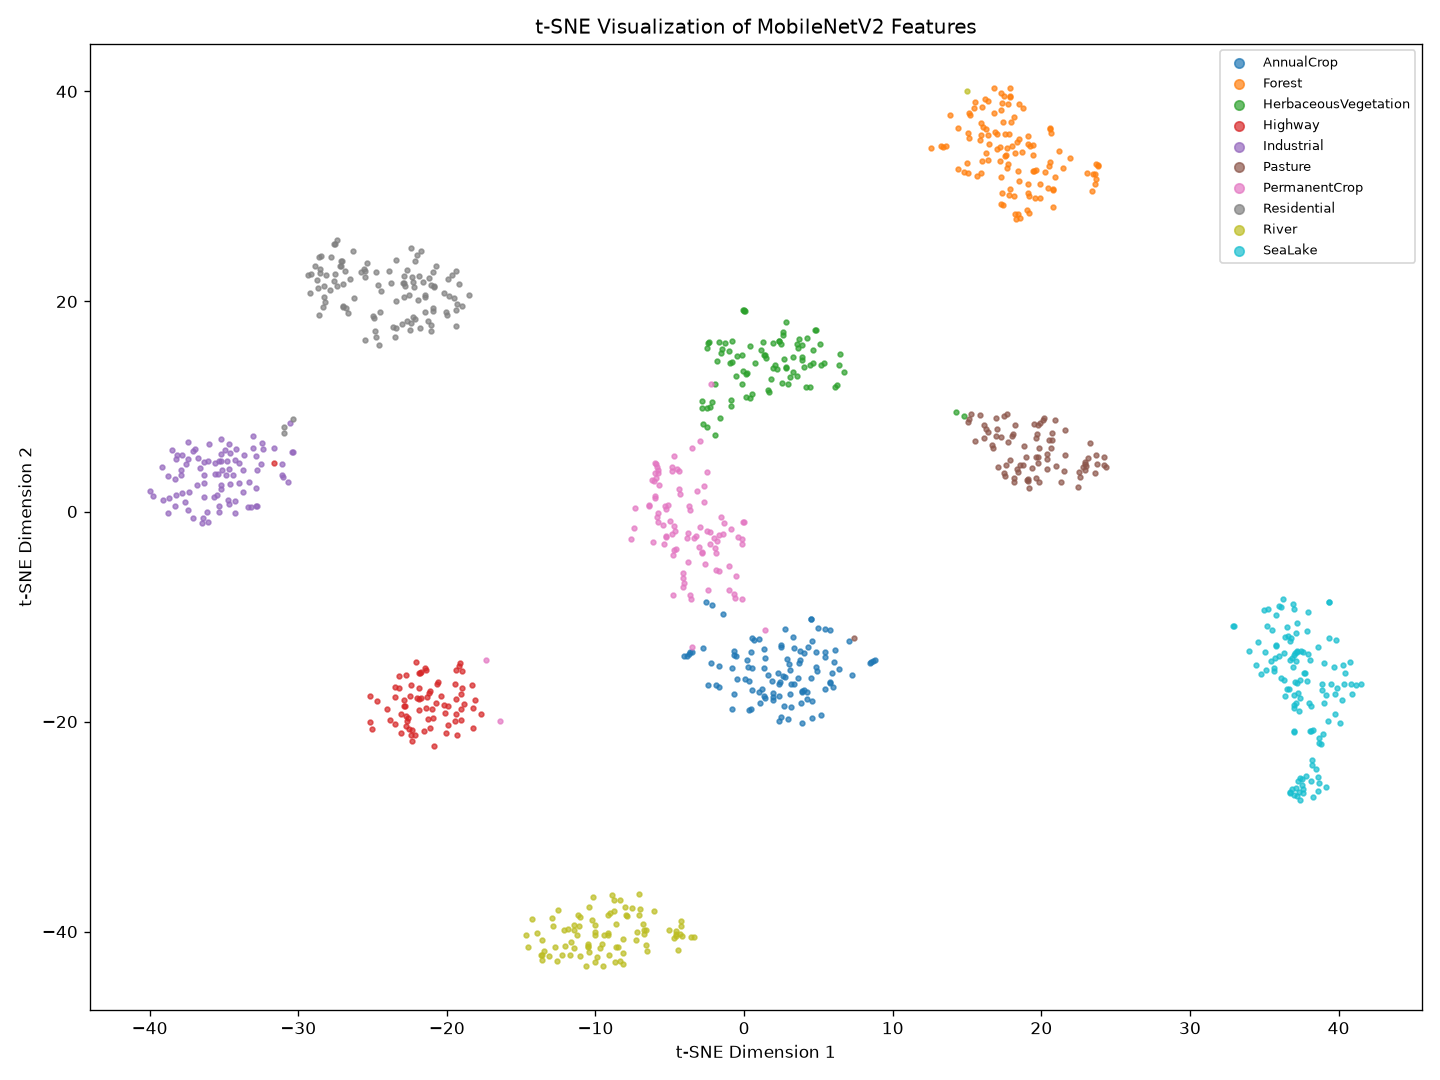

In [9]:
display(Image(filename=str(FIGURES / "mobilenet_v2_tsne.png")))


## 7. Data-Efficiency Experiment

Additional scratch CNN experiments were performed with seed 4 at 5%, 10%, and 25% training-data fractions.


In [10]:
metrics = pd.read_csv(RESULTS / "metrics.csv")
display(metrics[metrics["seed"] == 4])


,model,fraction,seed,accuracy,macro_f1
45,scratch_cnn,0.05,4,0.746914,0.739583
46,scratch_cnn,0.10,4,0.816790,0.809178
47,scratch_cnn,0.25,4,0.874321,0.868068


## 8. Conclusion

MobileNetV2 achieved 98.30% test accuracy and 98.20% Macro-F1. Error analysis identified confusion among visually similar agricultural classes. Grad-CAM was too coarse to explain single predictions (control experiment 5.1), the confidence-drop masking only makes sense together with that control, and t-SNE showed 10 clear groups of learned features.

### Limitations
- Grad-CAM here is very coarse (2 x 2 cells) and mostly points to the lower-right, so it is not evidence of model reasoning.
- Masking can introduce artificial image patterns.
- t-SNE does not preserve every original feature relationship.
- Results may not generalize to other satellite datasets.


## 9. Extra checks (added by Nitin, with Claude; Rohan has not reviewed this section)

Sections 1 to 8 show what Rohan saved. This section **re-scores the model on the CPU** to check those files, and adds a few numbers that were missing: a sorted per-class table, a count of the most confused pairs, real examples with the model's confidence, and how sure the model is when it is right and when it is wrong. It trains nothing and writes only `results/figures/most_confused_pairs.png`.

In [11]:
import sys

import numpy as np
import torch
from PIL import Image

sys.path.insert(0, str(project_root))
from src.dataset import EuroSATDataset
from src.train import build_model
from src.utils import DATA_DIR, MODELS_DIR

RUN = 'mobilenet_v2_full_frac1_seed0'
CLASSES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
           'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

model, _ = build_model('mobilenet_v2_full')
model.load_state_dict(torch.load(MODELS_DIR / f'{RUN}.pth', map_location='cpu', weights_only=True))   # weights_only: safe loading
model.eval()

test_set = EuroSATDataset('test')
test_df = test_set.df
labels = test_df['label'].to_numpy()

probabilities = []
with torch.no_grad():
    for start in range(0, len(test_set), 256):
        batch = torch.stack([test_set[i][0] for i in range(start, min(start + 256, len(test_set)))])
        probabilities.append(torch.softmax(model(batch), dim=1))
probabilities = torch.cat(probabilities).numpy()
predictions = probabilities.argmax(axis=1)
top_prob = probabilities.max(axis=1)

mine = pd.crosstab(pd.Series(labels, name='actual'), pd.Series(predictions, name='predicted')).reindex(
    index=range(10), columns=range(10), fill_value=0).to_numpy()
print(f'Correct on this run: {int((predictions == labels).sum())} of {len(labels)}  (Rohan saved {int(np.trace(cm.values))})')
print(f'Cells that differ from his saved matrix (sum of absolute differences): {int(np.abs(mine - cm.values).sum())}')

Correct on this run: 3981 of 4050  (Rohan saved 3981)
Cells that differ from his saved matrix (sum of absolute differences): 0


### 9.1 Per class, hardest first

Recall = of all real images of the class, how many we found. Precision = of all images we called this class, how many really were.

In [12]:
per_class = report.loc[CLASSES, ['precision', 'recall', 'f1-score', 'support']].copy()
per_class['support'] = per_class['support'].astype(int)
per_class.sort_values('recall').round(3)

,precision,recall,f1-score,support
PermanentCrop,0.968,0.960,0.964,375
AnnualCrop,0.982,0.971,0.977,450
HerbaceousVegetation,0.987,0.976,0.981,450
Pasture,0.951,0.977,0.964,300
Highway,0.973,0.979,0.976,375
Industrial,0.989,0.981,0.985,375
River,0.989,0.987,0.988,375
Residential,0.989,0.996,0.992,450
Forest,0.993,0.998,0.996,450
SeaLake,0.996,1.000,0.998,450


### 9.2 The most confused pairs

Read "7 x AnnualCrop -> PermanentCrop" as: seven real AnnualCrop images were called PermanentCrop.

In [13]:
pairs = sorted(((int(cm.loc[a, p]), a, p) for a in CLASSES for p in CLASSES if a != p and cm.loc[a, p] > 0),
               key=lambda t: (-t[0], t[1], t[2]))
mistakes_total = sum(t[0] for t in pairs)
print(f'{len(pairs)} different (actual -> predicted) pairs happened, {mistakes_total} mistakes in total.\n')
for count, actual, predicted in pairs[:8]:
    print(f'  {count} x {actual:22s} -> {predicted}')

crops = {'AnnualCrop', 'PermanentCrop', 'Pasture', 'HerbaceousVegetation'}
inside = sum(t[0] for t in pairs if t[1] in crops and t[2] in crops)
print(f'\nThe 6 biggest pairs are {sum(t[0] for t in pairs[:6])} of {mistakes_total} mistakes.')
print(f'Both the real and the predicted class are crop or vegetation classes: {inside} of {mistakes_total} ({inside / mistakes_total:.0%}).')

29 different (actual -> predicted) pairs happened, 69 mistakes in total.

  7 x AnnualCrop             -> PermanentCrop
  5 x AnnualCrop             -> Pasture
  5 x HerbaceousVegetation   -> Pasture
  5 x HerbaceousVegetation   -> PermanentCrop
  4 x Highway                -> River
  4 x Pasture                -> AnnualCrop
  3 x Industrial             -> Highway
  3 x Industrial             -> Residential

The 6 biggest pairs are 30 of 69 mistakes.
Both the real and the predicted class are crop or vegetation classes: 36 of 69 (52%).


### 9.3 Real examples of the 6 biggest pairs, with the model's confidence

The first four mistakes of each pair in `results/misclassified_images.csv` (a fixed rule, not hand-picked). The number is how sure the model was of its wrong answer. (Section 3.1 shows three examples per pair without the confidence.)

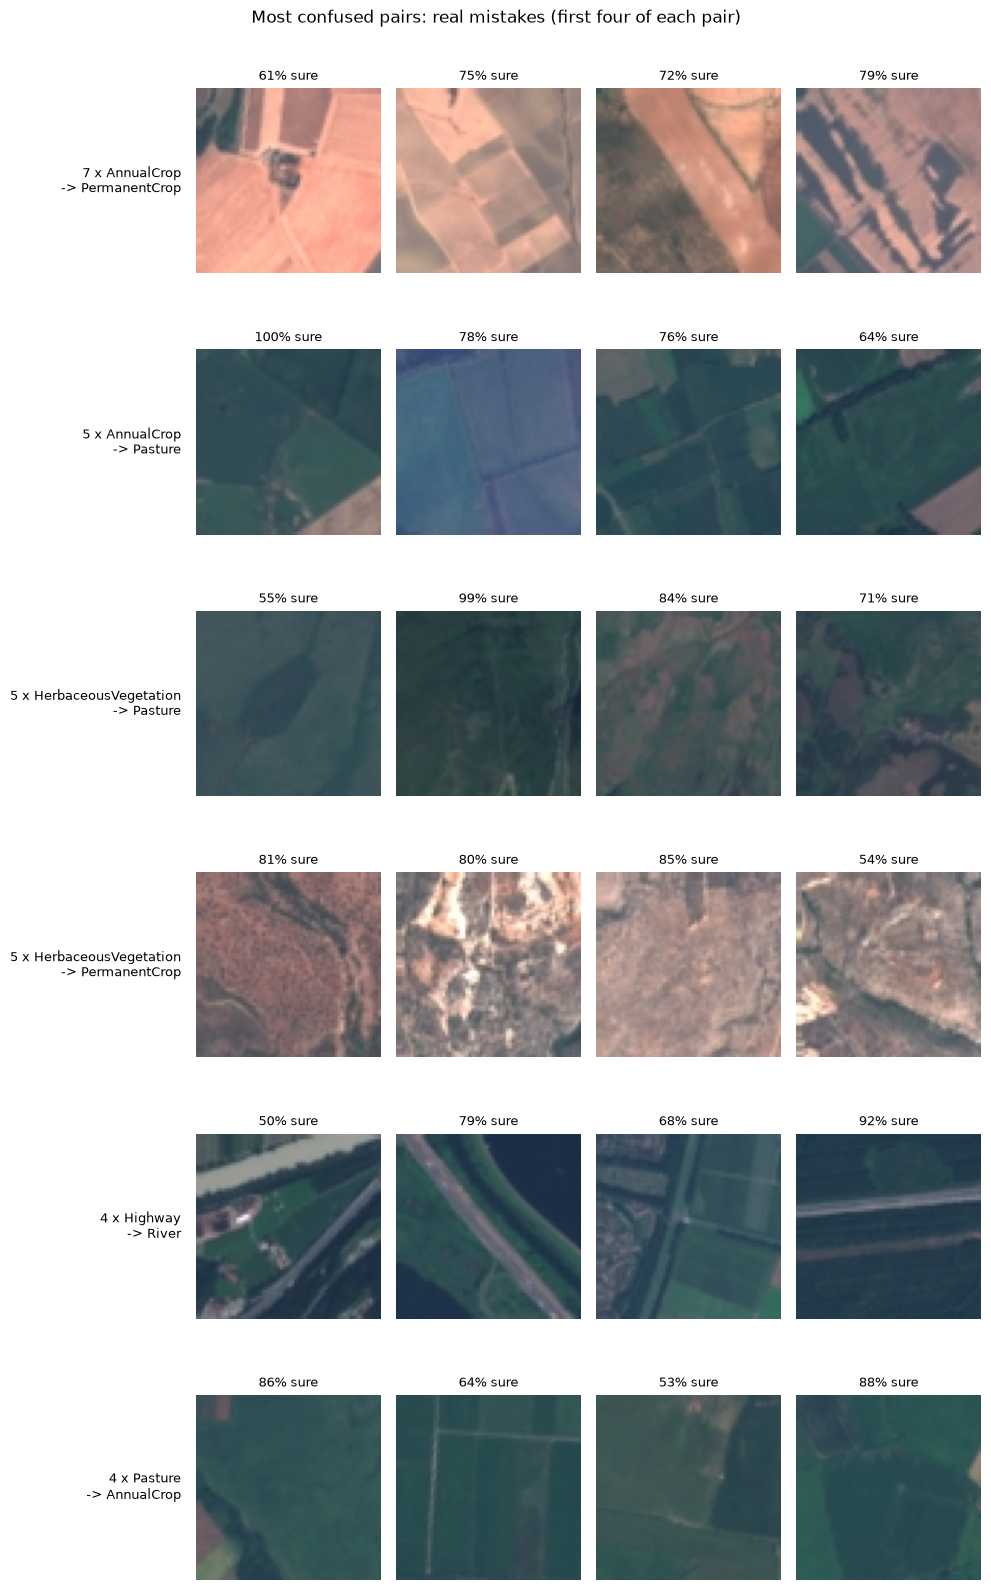

In [14]:
mistakes = pd.read_csv(RESULTS / 'misclassified_images.csv')
row_of_path = {p: i for i, p in enumerate(test_df['path'])}
top_pairs = pairs[:6]

fig, axes = plt.subplots(len(top_pairs), 4, figsize=(10, 2.7 * len(top_pairs)))
for r, (count, actual, predicted) in enumerate(top_pairs):
    chosen = mistakes[(mistakes['actual_class'] == actual) & (mistakes['predicted_class'] == predicted)].head(4)
    for c in range(4):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(chosen):
            row = chosen.iloc[c]
            ax.imshow(Image.open(DATA_DIR / row['path']).convert('RGB'))
            ax.set_title(f"{top_prob[row_of_path[row['path']]]:.0%} sure", fontsize=9)
    axes[r, 0].text(-0.08, 0.5, f'{count} x {actual}\n-> {predicted}', transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=9)
fig.suptitle('Most confused pairs: real mistakes (first four of each pair)', y=0.995)
fig.tight_layout()
fig.savefig(FIGURES / 'most_confused_pairs.png', dpi=110, bbox_inches='tight')
plt.show()

### 9.4 Is the model unsure when it is wrong?

If mistakes came with low confidence, a "send to a human when unsure" rule would catch them.

In [15]:
wrong = predictions != labels
print(f'Mean confidence when right: {top_prob[~wrong].mean():.3f}   (median {np.median(top_prob[~wrong]):.3f})')
print(f'Mean confidence when wrong: {top_prob[wrong].mean():.3f}   (median {np.median(top_prob[wrong]):.3f})')
for limit in (0.6, 0.8, 0.9):
    print(f'Mistakes below {limit:.0%} confidence: {int((top_prob[wrong] < limit).sum())} of {int(wrong.sum())}'
          f'   | correct answers below {limit:.0%}: {int((top_prob[~wrong] < limit).sum())} of {int((~wrong).sum())}')

Mean confidence when right: 0.990   (median 1.000)
Mean confidence when wrong: 0.763   (median 0.772)
Mistakes below 60% confidence: 10 of 69   | correct answers below 60%: 19 of 3981
Mistakes below 80% confidence: 39 of 69   | correct answers below 80%: 60 of 3981
Mistakes below 90% confidence: 56 of 69   | correct answers below 90%: 107 of 3981


### 9.5 What we learned (DRAFT, written with Claude from the numbers in this notebook; Rohan has not confirmed it)

1. **Overall.** 3,981 of 4,050 test images are right: accuracy 98.30%, macro-F1 0.982, 69 mistakes (1.7%). One model, one seed, so treat the second decimal with care.
2. **Easy and hard classes.** SeaLake (recall 1.000), Forest (0.998) and Residential (0.996) are almost perfect. The hardest are PermanentCrop (0.960), AnnualCrop (0.971) and HerbaceousVegetation (0.976). Pasture has the lowest precision (0.951): other green classes get called Pasture.
3. **Where the mistakes are.** 36 of the 69 mistakes (52%) are between the four crop and vegetation classes; the biggest pair is AnnualCrop -> PermanentCrop (7). In the examples many tiles show bare or dark ground, a field edge or a mix of fields, which even a person could not label with certainty from 64 x 64 pixels. For Highway -> River (4) the road runs next to a river or water, so both classes are in the tile. These reasons come from looking at examples; we did not test them.
4. **Confidence.** Right answers average 99.0% confidence, wrong ones 76.3%. A "send to a human if under 80% sure" rule would catch 39 of the 69 mistakes but would also flag 60 correct answers. The threshold was looked at on the test set, so it is an illustration, not a tuned rule.
5. **Grad-CAM, honestly.** The heat maps are soft blobs because the last MobileNetV2 block is only 2 x 2 cells for a 64 x 64 image. The control in 5.1 agrees with that caution: hiding the hottest 25% cost 0.064 of confidence, the coldest 25% cost 0.061 and a random square 0.089, and the hottest quarter was the bottom-right in 80% of 200 images (the top-left in none). **The heat maps did not pick out a part of the image that matters more than the rest**, so we use them as pictures, not as proof of what the model sees.
6. **t-SNE.** The 10 classes form 10 clear groups. PermanentCrop sits between HerbaceousVegetation and AnnualCrop with a few stray points, and a few Residential dots sit at the edge of Industrial, which matches the confusion matrix. Only which points are neighbours is meaningful in t-SNE, not the distance between groups or the size of a group.
7. **Limits.** 69 mistakes is a small number (4 against 5 is noise), one seed, and the test set was used once for this model only.